<a href="https://colab.research.google.com/github/abhi-7-7/Flight_Delay_Prediction/blob/main/Notebooks/02_Model_Application.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost joblib

In [32]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    precision_recall_curve
)

from xgboost import XGBClassifier

RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.


In [33]:
DATA_DIR = "/content"

def locate_csv(filename):
    possible_paths = [
        os.path.join(DATA_DIR, filename),
        filename
    ]

    for path in possible_paths:
        if os.path.isfile(path):
            return path

    raise FileNotFoundError(
        f"{filename} not found. "
        "Upload the file or update DATA_DIR."
    )

train_path = locate_csv("train.csv")
val_path = locate_csv("validation.csv")
test_path = locate_csv("test.csv")

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("Train:", train_df.shape, train_path)
print("Validation:", val_df.shape, val_path)
print("Test:", test_df.shape, test_path)

display(train_df.head())

Train: (217727, 19) /content/train.csv
Validation: (55628, 19) /content/validation.csv
Test: (53991, 19) /content/test.csv


,date,split,y,carrier,origin,dest_grouped,flight,distance,sched_minute,sched_arr_minute,scheduled_origin_hour_count,hour_sin,hour_cos,arr_hour_sin,arr_hour_cos,weekday_sin,weekday_cos,year_day_sin,year_day_cos
0,2013-01-01,train,0,UA,EWR,IAH,1545,1400,15,19,2,0.965926,2.588190e-01,0.866025,-0.500000,0.781831,0.62349,0.0,1.0
1,2013-01-01,train,1,UA,LGA,IAH,1714,1416,29,30,1,0.965926,2.588190e-01,0.866025,-0.500000,0.781831,0.62349,0.0,1.0
2,2013-01-01,train,1,AA,JFK,MIA,1141,1089,40,50,3,0.965926,2.588190e-01,0.866025,-0.500000,0.781831,0.62349,0.0,1.0
3,2013-01-01,train,0,B6,JFK,BQN,725,1576,45,22,3,0.965926,2.588190e-01,0.500000,-0.866025,0.781831,0.62349,0.0,1.0
4,2013-01-01,train,0,DL,LGA,ATL,461,762,0,37,17,1.000000,6.123234e-17,0.866025,-0.500000,0.781831,0.62349,0.0,1.0


In [34]:
TARGET = "y"

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Missing target values:", df[TARGET].isna().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Target distribution:")
    print(df[TARGET].value_counts(normalize=True).sort_index())

    assert TARGET in df.columns
    assert df[TARGET].notna().all()
    assert set(df[TARGET].unique()).issubset({0, 1})

print("\nTarget validation passed.")


--- Train ---
Shape: (217727, 19)
Missing target values: 0
Duplicate rows: 0
Target distribution:
y
0    0.736261
1    0.263739
Name: proportion, dtype: float64

--- Validation ---
Shape: (55628, 19)
Missing target values: 0
Duplicate rows: 0
Target distribution:
y
0    0.843047
1    0.156953
Name: proportion, dtype: float64

--- Test ---
Shape: (53991, 19)
Missing target values: 0
Duplicate rows: 0
Target distribution:
y
0    0.741698
1    0.258302
Name: proportion, dtype: float64

Target validation passed.


y,On-time (<15 min),Delayed (15+ min)
Train,73.63,26.37
Validation,84.30,15.70
Test,74.17,25.83


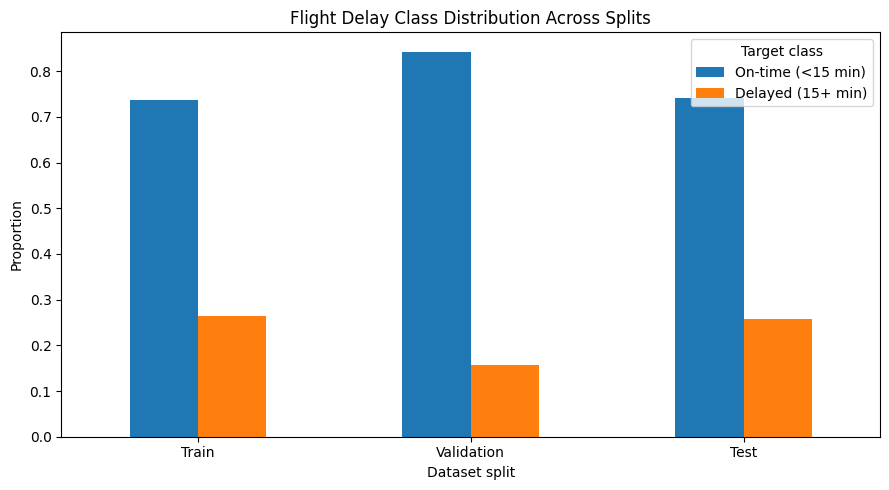

In [35]:
class_dist = pd.DataFrame({
    "Train": train_df["y"].value_counts(normalize=True),
    "Validation": val_df["y"].value_counts(normalize=True),
    "Test": test_df["y"].value_counts(normalize=True)
}).T.rename(columns={0: "On-time (<15 min)", 1: "Delayed (15+ min)"})

display((class_dist * 100).round(2))

class_dist.plot(kind="bar", figsize=(9, 5))
plt.title("Flight Delay Class Distribution Across Splits")
plt.ylabel("Proportion")
plt.xlabel("Dataset split")
plt.xticks(rotation=0)
plt.legend(title="Target class")
plt.tight_layout()
plt.show()

In [36]:
TARGET = "y"

categorical_features = [
    "carrier",
    "origin",
    "dest_grouped",
    "flight"
]

numeric_features = [
    "distance",
    "sched_minute",
    "sched_arr_minute",
    "scheduled_origin_hour_count",
    "hour_sin",
    "hour_cos",
    "arr_hour_sin",
    "arr_hour_cos",
    "weekday_sin",
    "weekday_cos",
    "year_day_sin",
    "year_day_cos"
]

feature_columns = categorical_features + numeric_features

# Check that expected features exist
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = set(feature_columns + [TARGET]) - set(df.columns)
    assert not missing, f"{name} is missing columns: {missing}"

X_train = train_df[feature_columns].copy()
y_train = train_df[TARGET].astype(int).copy()

X_val = val_df[feature_columns].copy()
y_val = val_df[TARGET].astype(int).copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].astype(int).copy()

print("Number of features:", len(feature_columns))
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Number of features: 16
Training samples: 217727
Validation samples: 55628
Test samples: 53991


,dataset_split,month,flights,delay_rate_pct
0,Test,2013-11,26971,18.10
1,Test,2013-12,27020,33.55
2,Train,2013-01,26398,23.49
3,Train,2013-02,23611,23.78
4,Train,2013-03,27902,23.60
5,Train,2013-04,27564,28.75
6,Train,2013-05,28128,22.67
7,Train,2013-06,27075,31.52
8,Train,2013-07,28293,32.21
9,Train,2013-08,28756,24.60


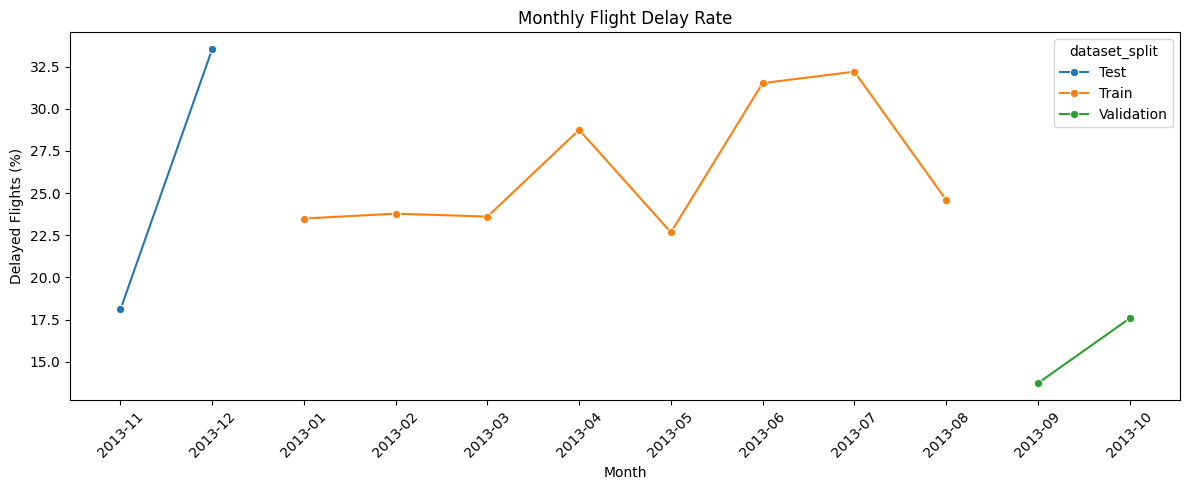

In [37]:
all_splits = pd.concat([
    train_df.assign(dataset_split="Train"),
    val_df.assign(dataset_split="Validation"),
    test_df.assign(dataset_split="Test")
], ignore_index=True)

all_splits["date"] = pd.to_datetime(
    all_splits["date"],
    errors="raise"
)

all_splits["month"] = (
    all_splits["date"].dt.to_period("M").astype(str)
)

monthly_stats = (
    all_splits.groupby(["dataset_split", "month"])
    .agg(
        flights=("y", "size"),
        delay_rate=("y", "mean")
    )
    .reset_index()
)

monthly_stats["delay_rate_pct"] = (
    monthly_stats["delay_rate"] * 100
)

display(
    monthly_stats[
        ["dataset_split", "month", "flights", "delay_rate_pct"]
    ].round(2)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_stats,
    x="month",
    y="delay_rate_pct",
    hue="dataset_split",
    marker="o"
)

plt.title("Monthly Flight Delay Rate")
plt.xlabel("Month")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

y,Not Delayed,Delayed
Train,73.63,26.37
Validation,84.30,15.70
Test,74.17,25.83


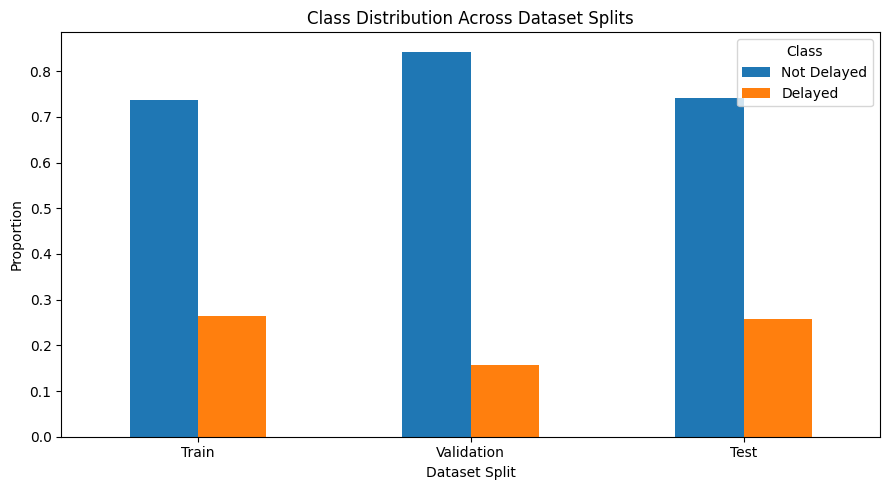

In [38]:
class_dist = pd.DataFrame({
    "Train": train_df["y"].value_counts(normalize=True),
    "Validation": val_df["y"].value_counts(normalize=True),
    "Test": test_df["y"].value_counts(normalize=True)
}).T.rename(columns={
    0: "Not Delayed",
    1: "Delayed"
})

display((class_dist * 100).round(2))

class_dist.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Class Distribution Across Dataset Splits")
plt.ylabel("Proportion")
plt.xlabel("Dataset Split")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

In [39]:
TARGET = "y"

categorical_features = [
    "carrier",
    "origin",
    "dest_grouped",
    "flight"
]

numeric_features = [
    "distance",
    "sched_minute",
    "sched_arr_minute",
    "scheduled_origin_hour_count",
    "hour_sin",
    "hour_cos",
    "arr_hour_sin",
    "arr_hour_cos",
    "weekday_sin",
    "weekday_cos",
    "year_day_sin",
    "year_day_cos"
]

feature_columns = (
    categorical_features + numeric_features
)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = set(feature_columns + [TARGET]) - set(df.columns)

    if missing:
        raise ValueError(
            f"{name} dataset is missing columns: {sorted(missing)}"
        )

X_train = train_df[feature_columns].copy()
y_train = train_df[TARGET].astype(int).copy()

X_val = val_df[feature_columns].copy()
y_val = val_df[TARGET].astype(int).copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[TARGET].astype(int).copy()

print("Features:", len(feature_columns))
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Features: 16
Training samples: 217727
Validation samples: 55628
Test samples: 53991


In [40]:
def build_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20
            )
        )
    ])

    preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ])

    return preprocessor


print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [41]:
lr_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

xgb_pipeline = Pipeline([
    ("preprocessor", build_preprocessor()),
    (
        "model",
        XGBClassifier(
            n_estimators=400,
            max_depth=5,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=-1,
            random_state=RANDOM_STATE
        )
    )
])

models = {
    "Logistic Regression": lr_pipeline,
    "XGBoost": xgb_pipeline
}

print("Models defined successfully.")

Models defined successfully.


In [42]:
print("Training Logistic Regression...")

lr_pipeline.fit(
    X_train,
    y_train
)

print("Logistic Regression training complete.")

print("\nTraining XGBoost...")

xgb_pipeline.fit(
    X_train,
    y_train
)

print("XGBoost training complete.")
print("\nBoth models have been trained.")

Training Logistic Regression...
Logistic Regression training complete.

Training XGBoost...
XGBoost training complete.

Both models have been trained.


In [43]:
baseline = DummyClassifier(
    strategy="prior"
)

baseline.fit(
    X_train,
    y_train
)

baseline_probabilities = baseline.predict_proba(
    X_val
)[:, 1]

baseline_results = {
    "Model": "Prior Baseline",
    "Average Precision": average_precision_score(
        y_val,
        baseline_probabilities
    ),
    "ROC-AUC": roc_auc_score(
        y_val,
        baseline_probabilities
    ),
    "Validation Base Rate": y_val.mean()
}

display(
    pd.DataFrame([baseline_results]).round(4)
)

,Model,Average Precision,ROC-AUC,Validation Base Rate
0,Prior Baseline,0.157,0.5,0.157


In [44]:
validation_results = []
validation_probabilities = {}

for name, model in models.items():

    probabilities = model.predict_proba(
        X_val
    )[:, 1]

    validation_probabilities[name] = probabilities

    validation_results.append({
        "Model": name,
        "Average Precision": average_precision_score(
            y_val,
            probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val,
            probabilities
        ),
        "Validation Base Rate": y_val.mean()
    })

validation_results_df = pd.DataFrame(
    validation_results
)

validation_results_df = (
    validation_results_df.sort_values(
        "Average Precision",
        ascending=False
    ).reset_index(drop=True)
)

display(validation_results_df.round(4))

,Model,Average Precision,ROC-AUC,Validation Base Rate
0,Logistic Regression,0.2348,0.6446,0.157
1,XGBoost,0.2301,0.6368,0.157


,Model,Average Precision,ROC-AUC,Validation Base Rate,PR-AUC Lift
0,Prior Baseline,0.1570,0.5000,0.157,1.0000
1,Logistic Regression,0.2348,0.6446,0.157,1.4958
2,XGBoost,0.2301,0.6368,0.157,1.4660


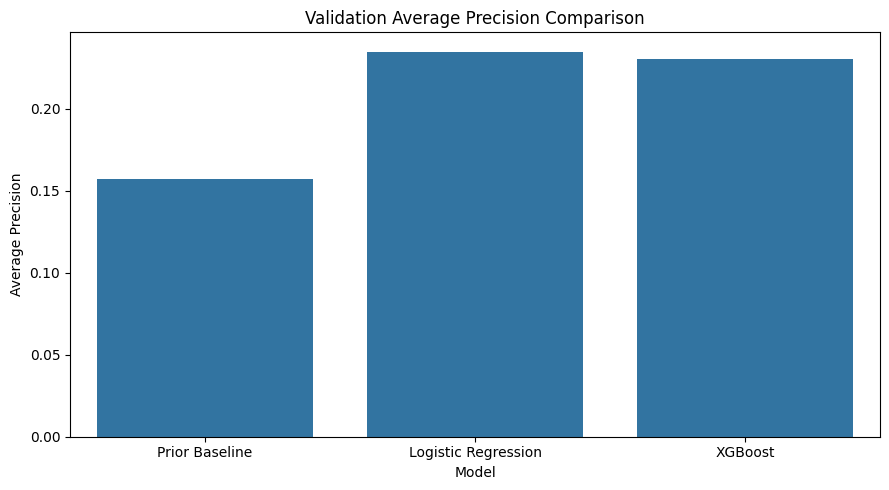

In [45]:
comparison_df = pd.concat([
    pd.DataFrame([baseline_results]),
    validation_results_df
], ignore_index=True)

comparison_df["PR-AUC Lift"] = (
    comparison_df["Average Precision"]
    / comparison_df["Validation Base Rate"]
)

display(comparison_df.round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Average Precision"
)

plt.title("Validation Average Precision Comparison")
plt.ylabel("Average Precision")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

In [46]:
best_model_name = validation_results_df.iloc[0]["Model"]
best_model = models[best_model_name]

val_probabilities = (
    validation_probabilities[best_model_name]
)

print("Selected model:", best_model_name)
print(
    "Validation Average Precision:",
    round(
        average_precision_score(
            y_val,
            val_probabilities
        ),
        4
    )
)

print(
    "Validation ROC-AUC:",
    round(
        roc_auc_score(
            y_val,
            val_probabilities
        ),
        4
    )
)

Selected model: Logistic Regression
Validation Average Precision: 0.2348
Validation ROC-AUC: 0.6446


In [47]:
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_val,
        val_probabilities
    )
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (
        precision_values[:-1]
        + recall_values[:-1]
        + 1e-12
    )
)

best_index = np.argmax(f1_values)

best_threshold = float(
    thresholds[best_index]
)

print("Selected model:", best_model_name)
print("Selected threshold:", round(best_threshold, 4))

print(
    "Validation precision:",
    round(precision_values[best_index], 4)
)

print(
    "Validation recall:",
    round(recall_values[best_index], 4)
)

print(
    "Validation F1-score:",
    round(f1_values[best_index], 4)
)

Selected model: Logistic Regression
Selected threshold: 0.2611
Validation precision: 0.2261
Validation recall: 0.5888
Validation F1-score: 0.3268


,Feature,Importance,Std
8,hour_sin,0.06777,0.00093
0,carrier,0.02643,0.00126
9,hour_cos,0.01473,0.00193
3,flight,0.00682,0.00084
13,weekday_cos,0.00640,0.00018
11,arr_hour_cos,0.00633,0.00031
7,scheduled_origin_hour_count,0.00497,0.00010
2,dest_grouped,0.00396,0.00062
10,arr_hour_sin,0.00240,0.00059
1,origin,0.00112,0.00017


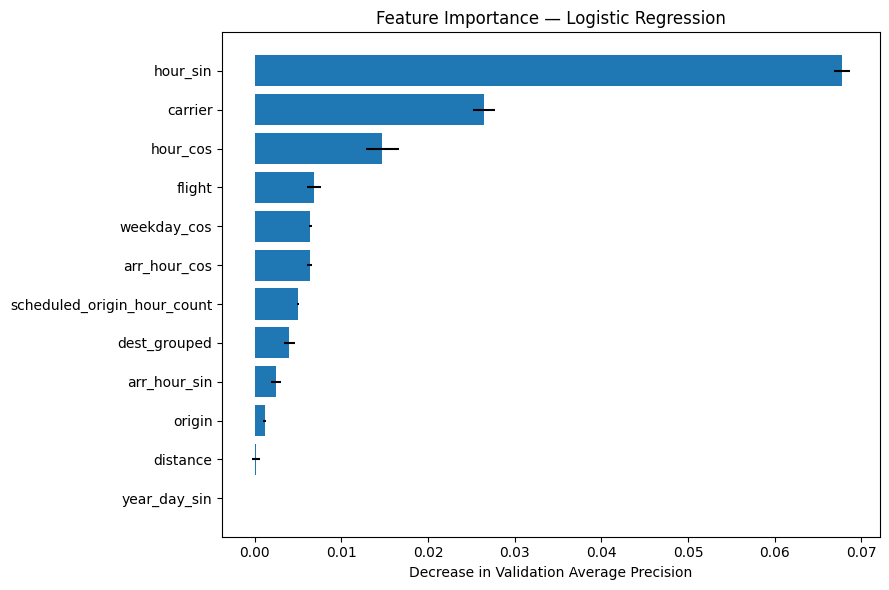

In [48]:
perm = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df.round(5))

top_features = (
    importance_df.head(12)
    .sort_values("Importance")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)

plt.xlabel("Decrease in Validation Average Precision")
plt.title(f"Feature Importance — {best_model_name}")
plt.tight_layout()
plt.show()

In [49]:
test_probabilities = best_model.predict_proba(
    X_test
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

test_metrics = {
    "selected_model": best_model_name,
    "threshold": best_threshold,
    "accuracy": accuracy_score(
        y_test,
        test_predictions
    ),
    "precision": precision_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "recall": recall_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "f1_score": f1_score(
        y_test,
        test_predictions,
        zero_division=0
    ),
    "average_precision": average_precision_score(
        y_test,
        test_probabilities
    ),
    "roc_auc": roc_auc_score(
        y_test,
        test_probabilities
    ),
    "test_base_rate": y_test.mean()
}

print("FINAL TEST RESULTS")
print("=" * 40)

for metric, value in test_metrics.items():

    if isinstance(
        value,
        (int, float, np.integer, np.floating)
    ):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

FINAL TEST RESULTS
selected_model: Logistic Regression
threshold: 0.2611
accuracy: 0.6349
precision: 0.3415
recall: 0.4456
f1_score: 0.3867
average_precision: 0.3359
roc_auc: 0.6070
test_base_rate: 0.2583


              precision    recall  f1-score   support

 Not Delayed       0.78      0.70      0.74     40045
     Delayed       0.34      0.45      0.39     13946

    accuracy                           0.63     53991
   macro avg       0.56      0.57      0.56     53991
weighted avg       0.67      0.63      0.65     53991



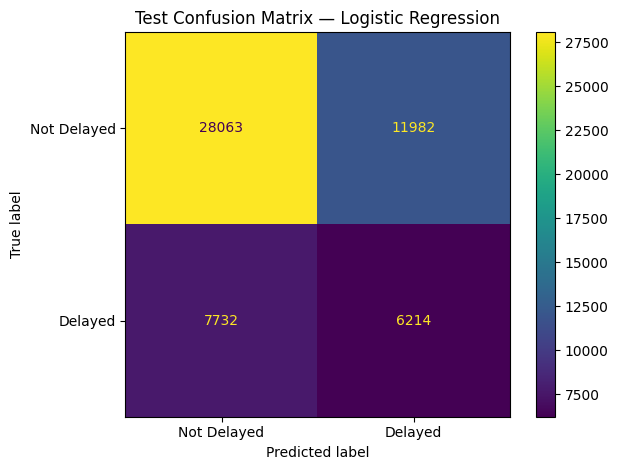

In [50]:
print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=[
            "Not Delayed",
            "Delayed"
        ],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Not Delayed",
        "Delayed"
    ]
)

disp.plot(values_format="d")

plt.title(
    f"Test Confusion Matrix — {best_model_name}"
)

plt.tight_layout()
plt.show()

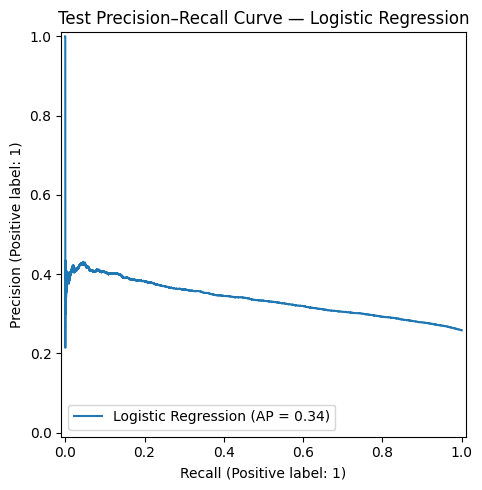

In [51]:
fig, ax = plt.subplots(figsize=(8, 5))

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name=best_model_name,
    ax=ax
)

ax.set_title(
    f"Test Precision–Recall Curve — {best_model_name}"
)

plt.tight_layout()
plt.show()

In [52]:
prediction_columns = [
    "date",
    "carrier",
    "origin",
    "dest_grouped",
    "flight",
    "y"
]

predictions_df = test_df[
    prediction_columns
].copy()

predictions_df = predictions_df.rename(
    columns={"y": "actual_y"}
)

predictions_df["predicted_probability"] = (
    test_probabilities
)

predictions_df["predicted_y"] = (
    test_predictions
)

predictions_df["threshold"] = best_threshold

predictions_df["error_type"] = np.select(
    [
        (
            (predictions_df["actual_y"] == 1)
            & (predictions_df["predicted_y"] == 0)
        ),
        (
            (predictions_df["actual_y"] == 0)
            & (predictions_df["predicted_y"] == 1)
        )
    ],
    [
        "False Negative",
        "False Positive"
    ],
    default="Correct Prediction"
)

display(predictions_df.head(10))

print(
    predictions_df["error_type"].value_counts()
)

,date,carrier,origin,dest_grouped,flight,actual_y,predicted_probability,predicted_y,threshold,error_type
0,2013-11-01,B6,JFK,PSE,745,0,0.274703,1,0.261087,False Positive
1,2013-11-01,B6,JFK,SYR,1816,1,0.442230,1,0.261087,Correct Prediction
2,2013-11-01,US,EWR,CLT,1895,0,0.037431,0,0.261087,Correct Prediction
3,2013-11-01,UA,LGA,IAH,1714,1,0.114375,0,0.261087,False Negative
4,2013-11-01,AA,JFK,MIA,2243,0,0.094367,0,0.261087,Correct Prediction
5,2013-11-01,UA,JFK,SFO,303,0,0.099345,0,0.261087,Correct Prediction
6,2013-11-01,US,LGA,DCA,2167,0,0.038920,0,0.261087,Correct Prediction
7,2013-11-01,US,LGA,BOS,2134,0,0.055084,0,0.261087,Correct Prediction
8,2013-11-01,DL,LGA,ATL,563,0,0.168627,0,0.261087,Correct Prediction
9,2013-11-01,DL,LGA,DTW,731,0,0.084739,0,0.261087,Correct Prediction


error_type
Correct Prediction    34277
False Positive        11982
False Negative         7732
Name: count, dtype: int64


In [53]:
OUTPUT_DIR = "/content/model_application_outputs"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# Save the complete fitted pipeline
joblib.dump(
    best_model,
    os.path.join(
        OUTPUT_DIR,
        "best_flight_delay_model.joblib"
    )
)

# Save validation model comparison
comparison_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "validation_model_comparison.csv"
    ),
    index=False
)

# Save final test metrics
with open(
    os.path.join(
        OUTPUT_DIR,
        "test_metrics.json"
    ),
    "w"
) as f:
    json.dump(
        test_metrics,
        f,
        indent=4
    )

# Save detailed test predictions
predictions_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "test_predictions.csv"
    ),
    index=False
)

# Save feature importance
importance_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "feature_importance.csv"
    ),
    index=False
)

# Save the selected threshold and model name
with open(
    os.path.join(
        OUTPUT_DIR,
        "model_metadata.json"
    ),
    "w"
) as f:
    json.dump(
        {
            "selected_model": best_model_name,
            "threshold": best_threshold,
            "target": TARGET,
            "features": feature_columns
        },
        f,
        indent=4
    )

print("Saved output files:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

Saved output files:
- best_flight_delay_model.joblib
- feature_importance.csv
- model_metadata.json
- test_metrics.json
- test_predictions.csv
- validation_model_comparison.csv


In [54]:
required_files = [
    "best_flight_delay_model.joblib",
    "validation_model_comparison.csv",
    "test_metrics.json",
    "test_predictions.csv",
    "feature_importance.csv",
    "model_metadata.json"
]

for filename in required_files:
    path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    assert os.path.isfile(path), (
        f"Missing output: {filename}"
    )

print("\nMODEL APPLICATION PIPELINE COMPLETED")
print("Selected model:", best_model_name)
print("Threshold:", round(best_threshold, 4))
print("Test Average Precision:",
      round(test_metrics["average_precision"], 4))
print("Test ROC-AUC:",
      round(test_metrics["roc_auc"], 4))
print("Output directory:", OUTPUT_DIR)


MODEL APPLICATION PIPELINE COMPLETED
Selected model: Logistic Regression
Threshold: 0.2611
Test Average Precision: 0.3359
Test ROC-AUC: 0.607
Output directory: /content/model_application_outputs


In [55]:
# FEATURE LEAKAGE AUDIT

audit_df = pd.concat([
    train_df.assign(dataset_split="Train"),
    val_df.assign(dataset_split="Validation"),
    test_df.assign(dataset_split="Test")
], ignore_index=True).copy()

audit_df["date"] = pd.to_datetime(audit_df["date"])

# Check required columns
required = [
    "date",
    "origin",
    "hour_sin",
    "hour_cos",
    "scheduled_origin_hour_count",
    "y"
]

missing = set(required) - set(audit_df.columns)
assert not missing, f"Missing columns: {missing}"

# Reconstruct scheduled hour from cyclic encoding
angle = np.arctan2(
    audit_df["hour_sin"],
    audit_df["hour_cos"]
)

audit_df["reconstructed_hour"] = (
    np.round((angle % (2 * np.pi)) * 24 / (2 * np.pi))
    .astype(int) % 24
)

# Recalculate counts by date, origin and scheduled hour
audit_df["reconstructed_count"] = (
    audit_df.groupby([
        "date",
        "origin",
        "reconstructed_hour"
    ])["origin"].transform("size")
)

# Compare saved feature with reconstructed count
audit_df["count_matches"] = np.isclose(
    audit_df["scheduled_origin_hour_count"],
    audit_df["reconstructed_count"]
)

print("Feature consistency check:")
print(
    audit_df.groupby("dataset_split").agg(
        rows=("y", "size"),
        match_rate=("count_matches", "mean"),
        stored_min=("scheduled_origin_hour_count", "min"),
        stored_max=("scheduled_origin_hour_count", "max")
    ).round(4)
)

print("\nExamples of mismatches:")
display(
    audit_df.loc[
        ~audit_df["count_matches"],
        [
            "date",
            "origin",
            "reconstructed_hour",
            "scheduled_origin_hour_count",
            "reconstructed_count"
        ]
    ].head(10)
)

Feature consistency check:
                 rows  match_rate  stored_min  stored_max
dataset_split                                            
Test            53991      0.7746           1          37
Train          217727      0.7230           1          38
Validation      55628      0.8530           1          36

Examples of mismatches:


,date,origin,reconstructed_hour,scheduled_origin_hour_count,reconstructed_count
8,2013-01-01,JFK,6,17,16
10,2013-01-01,JFK,6,17,16
11,2013-01-01,JFK,6,17,16
12,2013-01-01,JFK,6,17,16
23,2013-01-01,JFK,6,17,16
26,2013-01-01,JFK,6,17,16
27,2013-01-01,JFK,6,17,16
28,2013-01-01,JFK,6,17,16
35,2013-01-01,JFK,6,17,16
36,2013-01-01,JFK,6,17,16


In [56]:
# TEMPORAL DISTRIBUTION SHIFT ANALYSIS

splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

summary = []

for name, df in splits.items():
    dates = pd.to_datetime(df["date"])
    n = len(df)
    rate = df["y"].mean()

    # Approximate 95% confidence interval for delay rate
    se = np.sqrt(rate * (1 - rate) / n)

    summary.append({
        "Split": name,
        "Rows": n,
        "Start Date": dates.min().date(),
        "End Date": dates.max().date(),
        "Delay Rate (%)": rate * 100,
        "Approx CI Lower (%)": max(0, rate - 1.96 * se) * 100,
        "Approx CI Upper (%)": min(1, rate + 1.96 * se) * 100
    })

summary_df = pd.DataFrame(summary)

display(summary_df.round(2))

# Difference in delay rates, measured in percentage points
train_rate = train_df["y"].mean()

summary_df["Difference vs Train (pp)"] = (
    summary_df["Delay Rate (%)"] - train_rate * 100
)

print("\nDelay-rate difference relative to training:")
display(
    summary_df[
        ["Split", "Delay Rate (%)", "Difference vs Train (pp)"]
    ].round(2)
)

,Split,Rows,Start Date,End Date,Delay Rate (%),Approx CI Lower (%),Approx CI Upper (%)
0,Train,217727,2013-01-01,2013-08-31,26.37,26.19,26.56
1,Validation,55628,2013-09-01,2013-10-31,15.70,15.39,16.00
2,Test,53991,2013-11-01,2013-12-31,25.83,25.46,26.20



Delay-rate difference relative to training:


,Split,Delay Rate (%),Difference vs Train (pp)
0,Train,26.37,0.00
1,Validation,15.70,-10.68
2,Test,25.83,-0.54


,month,split,flights,delay_rate_pct
0,2013-01,Train,26398,23.49
1,2013-02,Train,23611,23.78
2,2013-03,Train,27902,23.60
3,2013-04,Train,27564,28.75
4,2013-05,Train,28128,22.67
5,2013-06,Train,27075,31.52
6,2013-07,Train,28293,32.21
7,2013-08,Train,28756,24.60
8,2013-09,Validation,27010,13.72
9,2013-10,Validation,28618,17.56


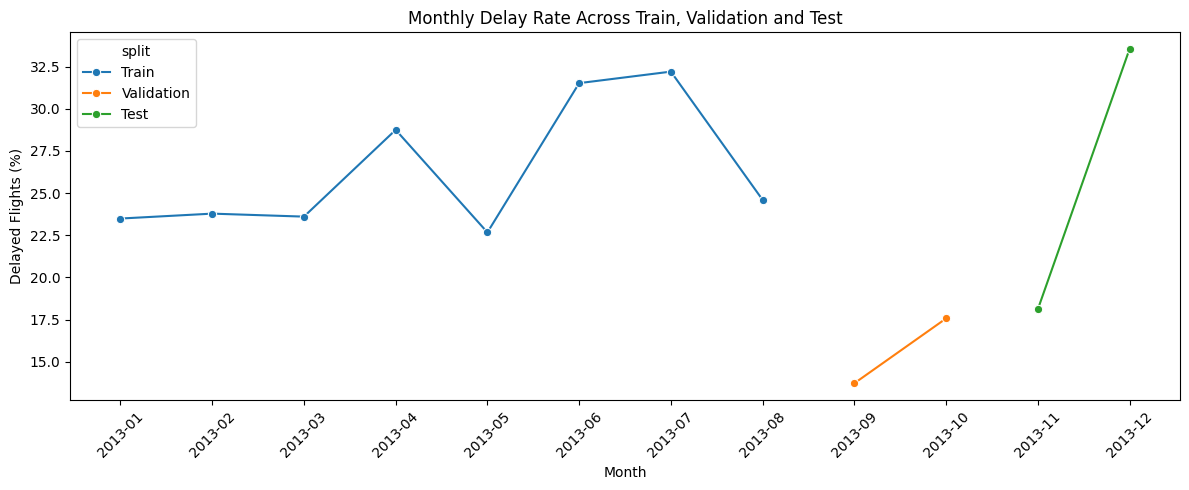

In [57]:
monthly_frames = []

for name, df in splits.items():
    temp = df[["date", "y"]].copy()
    temp["date"] = pd.to_datetime(temp["date"])
    temp["month"] = temp["date"].dt.to_period("M").astype(str)
    temp["split"] = name
    monthly_frames.append(temp)

monthly_df = pd.concat(
    monthly_frames,
    ignore_index=True
)

monthly_summary = (
    monthly_df.groupby(["month", "split"])
    .agg(
        flights=("y", "size"),
        delay_rate=("y", "mean")
    )
    .reset_index()
)

monthly_summary["delay_rate_pct"] = (
    monthly_summary["delay_rate"] * 100
)

display(
    monthly_summary[
        ["month", "split", "flights", "delay_rate_pct"]
    ].round(2)
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_summary,
    x="month",
    y="delay_rate_pct",
    hue="split",
    marker="o"
)

plt.title("Monthly Delay Rate Across Train, Validation and Test")
plt.xlabel("Month")
plt.ylabel("Delayed Flights (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [58]:
train_dates = pd.to_datetime(train_df["date"])
val_dates = pd.to_datetime(val_df["date"])
test_dates = pd.to_datetime(test_df["date"])

print("Train ends:", train_dates.max().date())
print("Validation starts:", val_dates.min().date())
print("Validation ends:", val_dates.max().date())
print("Test starts:", test_dates.min().date())

assert train_dates.max() < val_dates.min(), (
    "Train and validation date ranges overlap!"
)

assert val_dates.max() < test_dates.min(), (
    "Validation and test date ranges overlap!"
)

print("\nChronological split check passed.")

Train ends: 2013-08-31
Validation starts: 2013-09-01
Validation ends: 2013-10-31
Test starts: 2013-11-01

Chronological split check passed.


In [59]:
# Interactive Flight Delay Prediction Demo
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

# Select a sample of actual test flights for the demo
demo_flights = test_df.sample(
    n=min(100, len(test_df)),
    random_state=42
).copy()

demo_flights = demo_flights.reset_index(drop=True)

flight_options = {}

for i, row in demo_flights.iterrows():
    label = (
        f"{row['date']} | {row['carrier']} | "
        f"{row['origin']} → {row['dest_grouped']} | "
        f"Flight {row['flight']}"
    )
    flight_options[label] = i

flight_selector = widgets.Dropdown(
    options=flight_options,
    description="Select flight:",
    layout=widgets.Layout(width="95%"),
    style={"description_width": "initial"}
)

predict_button = widgets.Button(
    description="Predict Delay",
    button_style="primary",
    icon="check"
)

output = widgets.Output()

def predict_selected_flight(button):
    with output:
        clear_output(wait=True)

        row = demo_flights.iloc[flight_selector.value]

        # Use exactly the features expected by the trained model
        input_data = pd.DataFrame(
            [row[feature_columns].to_dict()],
            columns=feature_columns
        )

        probability = best_model.predict_proba(
            input_data
        )[0, 1]

        prediction = int(probability >= best_threshold)

        print("FLIGHT DETAILS")
        print("-" * 40)
        print(f"Date: {row['date']}")
        print(f"Carrier: {row['carrier']}")
        print(f"Origin: {row['origin']}")
        print(f"Destination group: {row['dest_grouped']}")
        print(f"Flight number: {row['flight']}")

        print("\nMODEL PREDICTION")
        print("-" * 40)
        print(f"Delay probability: {probability:.2%}")
        print(f"Decision threshold: {best_threshold:.4f}")

        if prediction == 1:
            print("Prediction: Delayed by 15+ minutes")
        else:
            print("Prediction: Not delayed by 15+ minutes")

        print("\nACTUAL OUTCOME (for retrospective demonstration)")
        actual = int(row["y"])
        print(
            "Actual: Delayed by 15+ minutes"
            if actual == 1
            else "Actual: Not delayed by 15+ minutes"
        )

predict_button.on_click(predict_selected_flight)

display(flight_selector, predict_button, output)

Dropdown(description='Select flight:', layout=Layout(width='95%'), options={'2013-12-22 | DL | EWR → DTW | Fli…

Button(button_style='primary', description='Predict Delay', icon='check', style=ButtonStyle())

Output()

In [60]:
# Model Performance Summary

metrics_to_display = {
    "Selected Model": best_model_name,
    "Decision Threshold": round(best_threshold, 4),
    "Average Precision (PR-AUC)": average_precision_score(
        y_test, test_probabilities
    ),
    "ROC-AUC": roc_auc_score(
        y_test, test_probabilities
    ),
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "Accuracy": accuracy_score(
        y_test, test_predictions
    )
}

display(
    pd.DataFrame(
        metrics_to_display.items(),
        columns=["Metric", "Value"]
    )
)

,Metric,Value
0,Selected Model,Logistic Regression
1,Decision Threshold,0.2611
2,Average Precision (PR-AUC),0.335927
3,ROC-AUC,0.607024
4,Precision,0.341504
5,Recall,0.445576
6,F1-Score,0.386659
7,Accuracy,0.634865
